# HR Employee Attrition Analysis
### Mengapa karyawan resign, dan siapa yang paling berisiko selanjutnya?

**Dataset:** IBM HR Analytics Employee Attrition & Performance (1,470 karyawan, 35 atribut)

---

## Business Problem

Sebuah perusahaan mengalami *employee attrition rate* di atas rata-rata industri. Tim People/HR
ingin memahami:

1. Seberapa besar masalah attrition ini, dan di bagian mana paling parah?
2. Faktor apa saja yang paling berkorelasi dengan keputusan karyawan resign?
3. Bisakah kita mengidentifikasi karyawan yang **berisiko tinggi resign saat ini juga**, sebelum mereka benar-benar keluar?
4. Rekomendasi retensi apa yang bisa langsung ditindaklanjuti oleh manajemen?

**Pendekatan analisis:** Data Cleaning → Exploratory Data Analysis → Risk Segmentation → Insight & Rekomendasi.


## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

COLOR_LEAVE = '#E15759'
COLOR_STAY = '#4E79A7'
COLOR_ACCENT = '#F28E2B'

raw = pd.read_csv('cleaned_hr_attrition.csv')  # already cleaned in this repo; raw source: IBM HR Analytics dataset (Kaggle)
raw.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,AttritionFlag,risk_overtime,risk_low_satisfaction,risk_low_worklife,risk_short_tenure,risk_low_income,risk_far_home,risk_no_promotion,RiskScore,RiskSegment
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,1,1,0,1,0,0,0,0,2,Medium Risk
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,0,0,1,0,0,0,0,0,1,Low Risk
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,1,1,0,0,1,1,0,0,3,Medium Risk
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,0,1,0,0,0,1,0,0,2,Medium Risk
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,0,0,1,0,1,0,0,0,2,Medium Risk


> Catatan: notebook ini bekerja di atas dataset yang sudah melalui tahap *cleaning* (lihat Bagian 2).
> File mentah asli (`WA_Fn-UseC_-HR-Employee-Attrition.csv`) bisa didapat dari Kaggle: *IBM HR Analytics Employee Attrition & Performance*.

## 2. Data Cleaning

Sebelum analisis, saya cek kualitas data terlebih dahulu:

- **Missing values:** tidak ada (0 dari 1,470 baris x 35 kolom) — dataset ini relatif bersih dari sumbernya.
- **Duplikat:** tidak ada baris duplikat.
- **Kolom konstan (tidak informatif):** `EmployeeCount` (selalu 1), `Over18` (selalu 'Y'), `StandardHours` (selalu 80).
  Kolom-kolom ini tidak punya variasi sehingga tidak berguna untuk analisis — saya buang.
- **Feature engineering tambahan** untuk mempermudah interpretasi bisnis:
  - `IncomeBand`: mengelompokkan `MonthlyIncome` ke kategori (<3K, 3K-6K, 6K-10K, 10K+)
  - `TenureBand`: mengelompokkan `YearsAtCompany` ke kategori (0-2, 3-5, 6-10, 10+ tahun)
  - `AttritionFlag`: versi numerik dari `Attrition` (1 = Yes, 0 = No) untuk agregasi


In [2]:
df = pd.read_csv('cleaned_hr_attrition.csv')
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df[['Age','Department','MonthlyIncome','IncomeBand','YearsAtCompany','TenureBand','Attrition']].head()


Shape: (1470, 45)
Missing values: 0


,Age,Department,MonthlyIncome,IncomeBand,YearsAtCompany,TenureBand,Attrition
0,41,Sales,5993,3K-6K,6,6-10 yrs,Yes
1,49,Research & Development,5130,3K-6K,10,6-10 yrs,No
2,37,Research & Development,2090,<3K,0,0-2 yrs,Yes
3,33,Research & Development,2909,<3K,8,6-10 yrs,No
4,27,Research & Development,3468,3K-6K,2,0-2 yrs,No


## 3. Overview: Seberapa Besar Masalahnya?

In [3]:
overall_rate = df['AttritionFlag'].mean() * 100
total_leavers = df['AttritionFlag'].sum()
print(f"Total karyawan     : {len(df)}")
print(f"Total yang resign  : {total_leavers}")
print(f"Attrition rate     : {overall_rate:.1f}%")


Total karyawan     : 1470
Total yang resign  : 237
Attrition rate     : 16.1%


**Insight:** Dari 1,470 karyawan, **237 orang (16.1%) resign**. Sebagai pembanding, rata-rata
attrition rate industri teknologi/professional services umumnya berkisar 10-15% per tahun — artinya
perusahaan ini sedikit di atas rata-rata dan layak untuk digali lebih dalam.

## 4. Attrition Berdasarkan Departemen

Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: AttritionFlag, dtype: float64


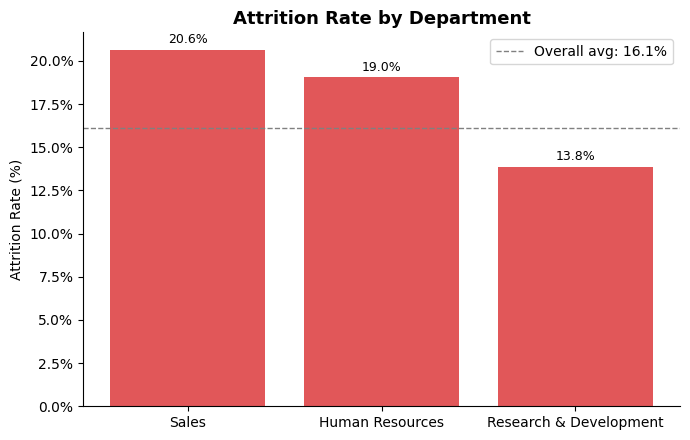

In [4]:
by_department = (df.groupby('Department')['AttritionFlag'].mean() * 100).sort_values(ascending=False)
print(by_department)

fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(by_department.index, by_department.values, color=COLOR_LEAVE)
ax.axhline(overall_rate, color='gray', linestyle='--', linewidth=1, label=f'Overall avg: {overall_rate:.1f}%')
ax.set_ylabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by Department', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.4, f'{b.get_height():.1f}%', ha='center', fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()


**Insight:** Departemen **Sales (20.6%)** dan **Human Resources (19.0%)** punya attrition rate
di atas rata-rata perusahaan, sementara **R&D (13.8%)** relatif lebih stabil. Ini sinyal awal bahwa
masalah retensi lebih terkonsentrasi di fungsi yang berhadapan langsung dengan target/tekanan eksternal (Sales) dan HR sendiri.

## 5. Attrition Berdasarkan Job Role (Lebih Detail)

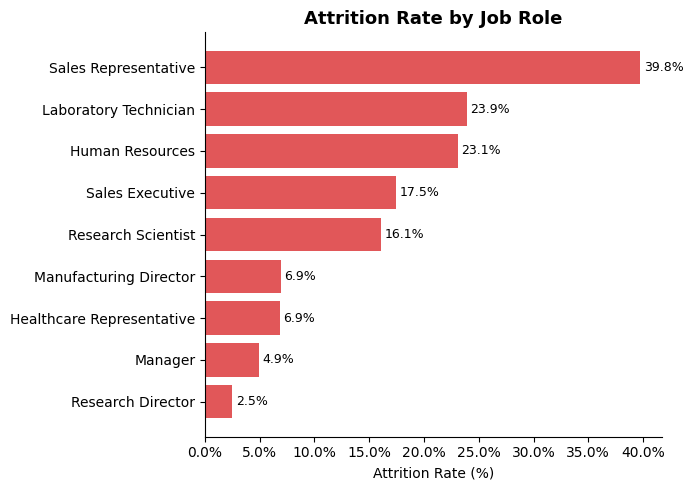

In [5]:
by_jobrole = (df.groupby('JobRole')['AttritionFlag'].mean() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.barh(by_jobrole.index, by_jobrole.values, color=COLOR_LEAVE)
ax.set_xlabel('Attrition Rate (%)')
ax.set_title('Attrition Rate by Job Role', fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for b in bars:
    ax.text(b.get_width()+0.3, b.get_y()+b.get_height()/2, f'{b.get_width():.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()


**Insight:** Setelah dipecah per role, ternyata **Sales Representative (39.8%)** adalah role
dengan attrition tertinggi di seluruh perusahaan — jauh di atas rata-rata departemen Sales itu sendiri.
Ini menunjukkan masalah attrition di Sales sebenarnya terkonsentrasi pada 1 role spesifik,
bukan merata ke semua role di departemen tersebut. **Laboratory Technician (23.9%)** dan **HR (23.1%)**
juga perlu perhatian.

## 6. Faktor Overtime

OverTime
Yes    30.528846
No     10.436433
Name: AttritionFlag, dtype: float64


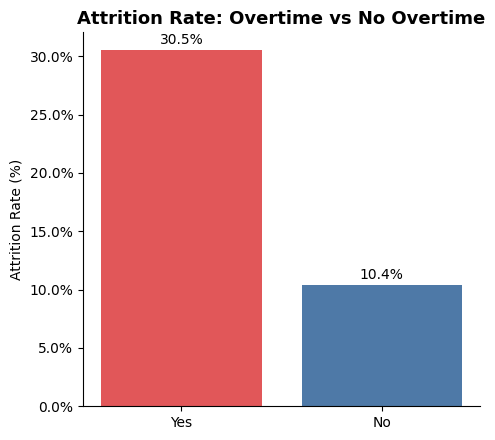

In [6]:
by_overtime = (df.groupby('OverTime')['AttritionFlag'].mean() * 100).sort_values(ascending=False)
print(by_overtime)

fig, ax = plt.subplots(figsize=(5,4.5))
bars = ax.bar(by_overtime.index, by_overtime.values, color=[COLOR_LEAVE, COLOR_STAY])
ax.set_ylabel('Attrition Rate (%)')
ax.set_title('Attrition Rate: Overtime vs No Overtime', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f'{b.get_height():.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


**Insight:** Karyawan yang lembur (`OverTime = Yes`) punya attrition rate **30.5%** — hampir
**3x lipat** dibanding yang tidak lembur (**10.4%**). Ini salah satu faktor paling kuat dalam dataset ini.

## 7. Faktor Income & Tenure

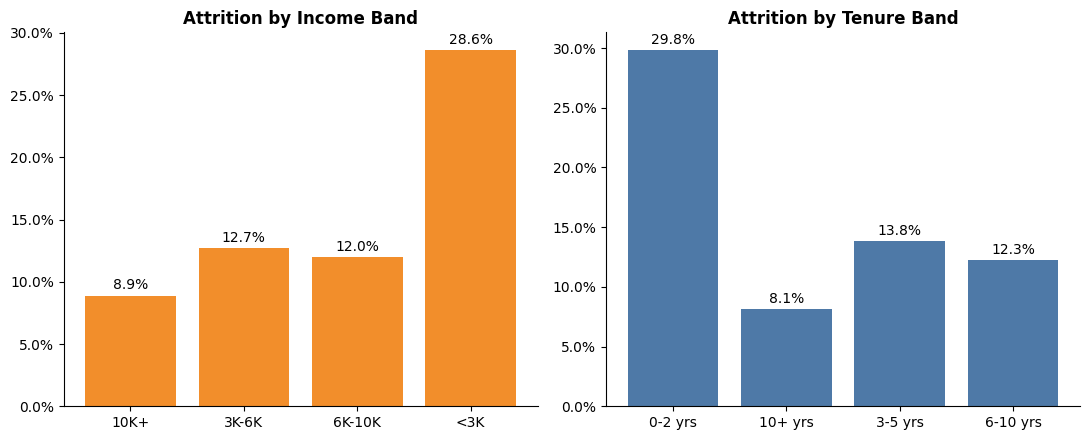

In [7]:
by_income = (df.groupby('IncomeBand')['AttritionFlag'].mean() * 100)
by_tenure = (df.groupby('TenureBand')['AttritionFlag'].mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
axes[0].bar(by_income.index.astype(str), by_income.values, color=COLOR_ACCENT)
axes[0].set_title('Attrition by Income Band', fontweight='bold')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for i,v in enumerate(by_income.values):
    axes[0].text(i, v+0.5, f'{v:.1f}%', ha='center')

axes[1].bar(by_tenure.index.astype(str), by_tenure.values, color=COLOR_STAY)
axes[1].set_title('Attrition by Tenure Band', fontweight='bold')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for i,v in enumerate(by_tenure.values):
    axes[1].text(i, v+0.5, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()


**Insight:**
- Karyawan dengan gaji **di bawah 3K** punya attrition **28.6%**, jauh di atas kelompok gaji lain.
- Karyawan dengan **tenure 0-2 tahun** (baru bergabung) punya attrition **29.8%** — 3.6x lebih tinggi
  dari karyawan dengan tenure 10+ tahun (8.1%). Artinya periode **kritis** ada di 2 tahun pertama masa kerja.

## 8. Risk Segmentation — Dari "Kenapa" ke "Siapa"

Setelah tahu faktor-faktor pendorong attrition, langkah berikutnya adalah membangun
**skor risiko sederhana dan mudah dijelaskan** ke HR (bukan black-box model), supaya
tim HR bisa langsung tahu karyawan mana yang perlu diprioritaskan untuk intervensi.

Setiap karyawan diberi 1 poin risiko untuk setiap kondisi berikut yang mereka alami:

| Faktor Risiko | Kondisi |
|---|---|
| Overtime | Ya |
| Kepuasan kerja rendah | JobSatisfaction ≤ 2 |
| Work-life balance buruk | WorkLifeBalance ≤ 2 |
| Tenure pendek | YearsAtCompany ≤ 2 |
| Gaji rendah | MonthlyIncome < 3000 |
| Jarak rumah jauh | DistanceFromHome ≥ 15 |
| Lama tidak promosi | YearsSinceLastPromotion ≥ 5 |

Total skor (0-7) lalu dikelompokkan jadi 3 segmen: **Low Risk (0-1)**, **Medium Risk (2-3)**, **High Risk (4+)**.


In [8]:
df['risk_overtime'] = (df['OverTime']=='Yes').astype(int)
df['risk_low_satisfaction'] = (df['JobSatisfaction']<=2).astype(int)
df['risk_low_worklife'] = (df['WorkLifeBalance']<=2).astype(int)
df['risk_short_tenure'] = (df['YearsAtCompany']<=2).astype(int)
df['risk_low_income'] = (df['MonthlyIncome']<3000).astype(int)
df['risk_far_home'] = (df['DistanceFromHome']>=15).astype(int)
df['risk_no_promotion'] = (df['YearsSinceLastPromotion']>=5).astype(int)

risk_cols = ['risk_overtime','risk_low_satisfaction','risk_low_worklife',
             'risk_short_tenure','risk_low_income','risk_far_home','risk_no_promotion']
df['RiskScore'] = df[risk_cols].sum(axis=1)

def risk_segment(score):
    if score >= 4: return 'High Risk'
    elif score >= 2: return 'Medium Risk'
    else: return 'Low Risk'

df['RiskSegment'] = df['RiskScore'].apply(risk_segment)

seg_summary = df.groupby('RiskSegment').agg(
    employees=('EmployeeNumber','count'),
    attrition_rate=('AttritionFlag', lambda x: x.mean()*100)
).reindex(['Low Risk','Medium Risk','High Risk'])
seg_summary


,employees,attrition_rate
RiskSegment,,
Low Risk,585,5.811966
Medium Risk,759,18.050066
High Risk,126,52.380952


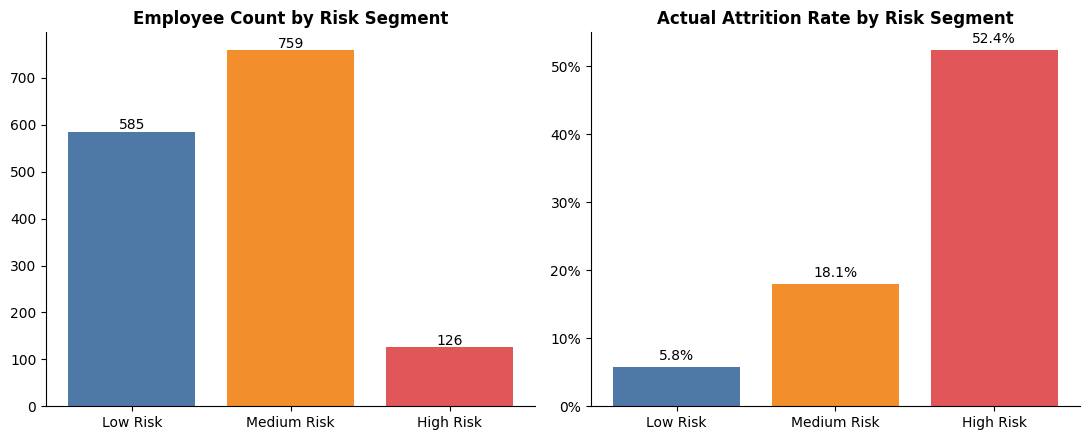

In [9]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5))
colors_seg = {'Low Risk': COLOR_STAY, 'Medium Risk': COLOR_ACCENT, 'High Risk': COLOR_LEAVE}
seg_order = ['Low Risk','Medium Risk','High Risk']

axes[0].bar(seg_order, seg_summary['employees'], color=[colors_seg[s] for s in seg_order])
axes[0].set_title('Employee Count by Risk Segment', fontweight='bold')
for i,v in enumerate(seg_summary['employees']):
    axes[0].text(i, v+5, str(int(v)), ha='center')

axes[1].bar(seg_order, seg_summary['attrition_rate'], color=[colors_seg[s] for s in seg_order])
axes[1].set_title('Actual Attrition Rate by Risk Segment', fontweight='bold')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for i,v in enumerate(seg_summary['attrition_rate']):
    axes[1].text(i, v+1, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()


**Validasi model sederhana ini bekerja dengan sangat baik:**

- **High Risk** (126 karyawan): attrition rate **52.4%** — lebih dari 1 dari 2 orang resign.
- **Medium Risk** (759 karyawan): attrition rate **18.1%**.
- **Low Risk** (585 karyawan): attrition rate hanya **5.8%**.

Artinya, tanpa perlu machine learning yang kompleks, HR sudah bisa memprioritaskan **126 karyawan
"High Risk"** ini sebagai target intervensi pertama — populasi kecil (8.6% dari total karyawan)
tapi menyumbang risiko resign yang jauh lebih besar dari rata-rata perusahaan.

## 9. Kesimpulan & Rekomendasi Bisnis

### Ringkasan Temuan
1. Attrition rate keseluruhan **16.1%**, dengan **Sales Representative (39.8%)** sebagai role paling berisiko.
2. **Overtime** adalah faktor tunggal terkuat: attrition 30.5% (lembur) vs 10.4% (tidak lembur).
3. **2 tahun pertama bekerja** adalah periode paling kritis (attrition 29.8%).
4. Gaji di bawah 3K berkontribusi signifikan terhadap keputusan resign (28.6%).
5. Model segmentasi risiko sederhana berhasil mengidentifikasi 126 karyawan "High Risk" dengan
   attrition rate 52.4% — 9x lebih tinggi dari segmen Low Risk.

### Rekomendasi Actionable
| # | Rekomendasi | Target |
|---|---|---|
| 1 | Audit beban kerja & kebijakan lembur, terutama di Sales & Lab | Karyawan dengan OverTime = Yes |
| 2 | Perkuat program onboarding & mentoring 24 bulan pertama | Karyawan tenure 0-2 tahun |
| 3 | Evaluasi struktur gaji untuk role dengan income <3K | Sales Representative, Lab Technician |
| 4 | Buat program retensi khusus untuk 126 karyawan "High Risk" (1-on-1 check-in, jalur karier jelas) | Segmen High Risk |
| 5 | Review ulang siklus promosi bagi karyawan yang sudah >5 tahun belum naik jabatan | Karyawan risk_no_promotion = 1 |

### Batasan Analisis
- Dataset ini adalah snapshot (bukan data historis), sehingga tidak menangkap tren dari waktu ke waktu.
- Risk score bersifat rule-based (mudah dijelaskan), bukan model prediktif — cocok untuk langkah awal;
  untuk versi lanjutan bisa dikembangkan dengan model klasifikasi (misal Logistic Regression / Random Forest)
  untuk mendapat skor probabilitas yang lebih presisi.
